# Part A — Train the Brain Tumor Classifier

This notebook trains **one model** that all four project demos will share.

**Before you run (Kaggle settings, right panel):**
1. **Add Input** → search `brain-tumor-mri-dataset` (by masoudnickparvar) → Add.
2. **Accelerator** → GPU T4 x2 (or P100).
3. **Internet** → On (needed to install `grad-cam` and download pretrained weights).

Then click **Run All**. It takes about 20–40 minutes.
At the end, download `best_model.pth` from the **Output** panel (`/kaggle/working/`).

## Step 0 — Install and import libraries
`timm` gives us pretrained models. `grad-cam` makes heatmaps.

In [2]:
!pip install -q grad-cam timm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import os, random, time, copy
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## Settings
All the numbers you may want to change are here in one place.

In [4]:
SEED       = 42
IMG_SIZE   = 224                 # EfficientNet-B0 standard input size
BATCH_SIZE = 32
EPOCHS     = 12
LR         = 1e-4
VAL_RATIO  = 0.15                # 15% of Training/ becomes validation
MODEL_NAME = "efficientnet_b0"
PRETRAINED = True
OUT_DIR    = Path("/kaggle/working/")
INPUT_ROOT = Path("/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(SEED)
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Step 1 — Find and load the data
The dataset has two folders, `Training/` and `Testing/`. Inside each, the **folder name is the label**
(`glioma`, `meningioma`, `notumor`, `pituitary`).

Kaggle sometimes changes the input path, so this code **searches** for the `Training` folder
instead of hard-coding the path.

In [5]:
def find_data_dir(root):
    for p in sorted(root.rglob("Training")):
        if p.is_dir() and (p.parent / "Testing").is_dir():
            return p.parent
    raise FileNotFoundError(f"No Training/ + Testing/ folders found under {root}. Did you add the dataset?")

DATA_DIR = find_data_dir(INPUT_ROOT)
print("Data folder:", DATA_DIR)

IMG_EXT = {".jpg", ".jpeg", ".png"}

def list_images(split_dir):
    rows = []
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        for f in class_dir.iterdir():
            if f.suffix.lower() in IMG_EXT:
                rows.append({"path": str(f), "label": class_dir.name})
    return pd.DataFrame(rows)

train_full_df = list_images(DATA_DIR / "Training")
test_df       = list_images(DATA_DIR / "Testing")

CLASS_NAMES = sorted(train_full_df["label"].unique())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
print("Classes:", CLASS_NAMES)
print(f"Training images: {len(train_full_df)} | Testing images: {len(test_df)}")

Data folder: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Training images: 5600 | Testing images: 1600


## Step 2 — Look at the data (EDA)
We check three things:
1. **Images per class.** If one class is much smaller, the model may be biased.
2. **Image sizes.** They are different, so we must resize.
3. **Sample images.** Just to see what the model will learn from.

,Training,Testing
label,,
glioma,1400,400
meningioma,1400,400
notumor,1400,400
pituitary,1400,400


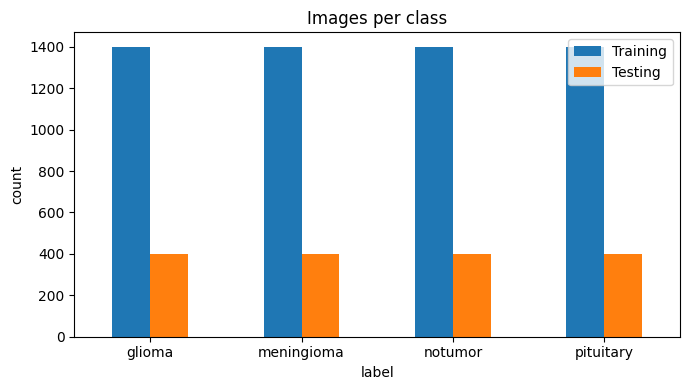

In [6]:
counts = pd.DataFrame({
    "Training": train_full_df["label"].value_counts(),
    "Testing":  test_df["label"].value_counts(),
}).loc[CLASS_NAMES]
display(counts)

counts.plot(kind="bar", figsize=(7, 4), title="Images per class")
plt.ylabel("count"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [7]:
sample_paths = train_full_df.sample(min(300, len(train_full_df)), random_state=SEED)["path"]
sizes = Counter(Image.open(p).size for p in sample_paths)
print("Most common image sizes (width, height) in a 300-image sample:")
for size, n in sizes.most_common(8):
    print(f"  {size}: {n}")

Most common image sizes (width, height) in a 300-image sample:
  (512, 512): 222
  (225, 225): 13
  (228, 221): 3
  (206, 244): 3
  (359, 449): 2
  (232, 217): 2
  (201, 251): 2
  (441, 442): 2


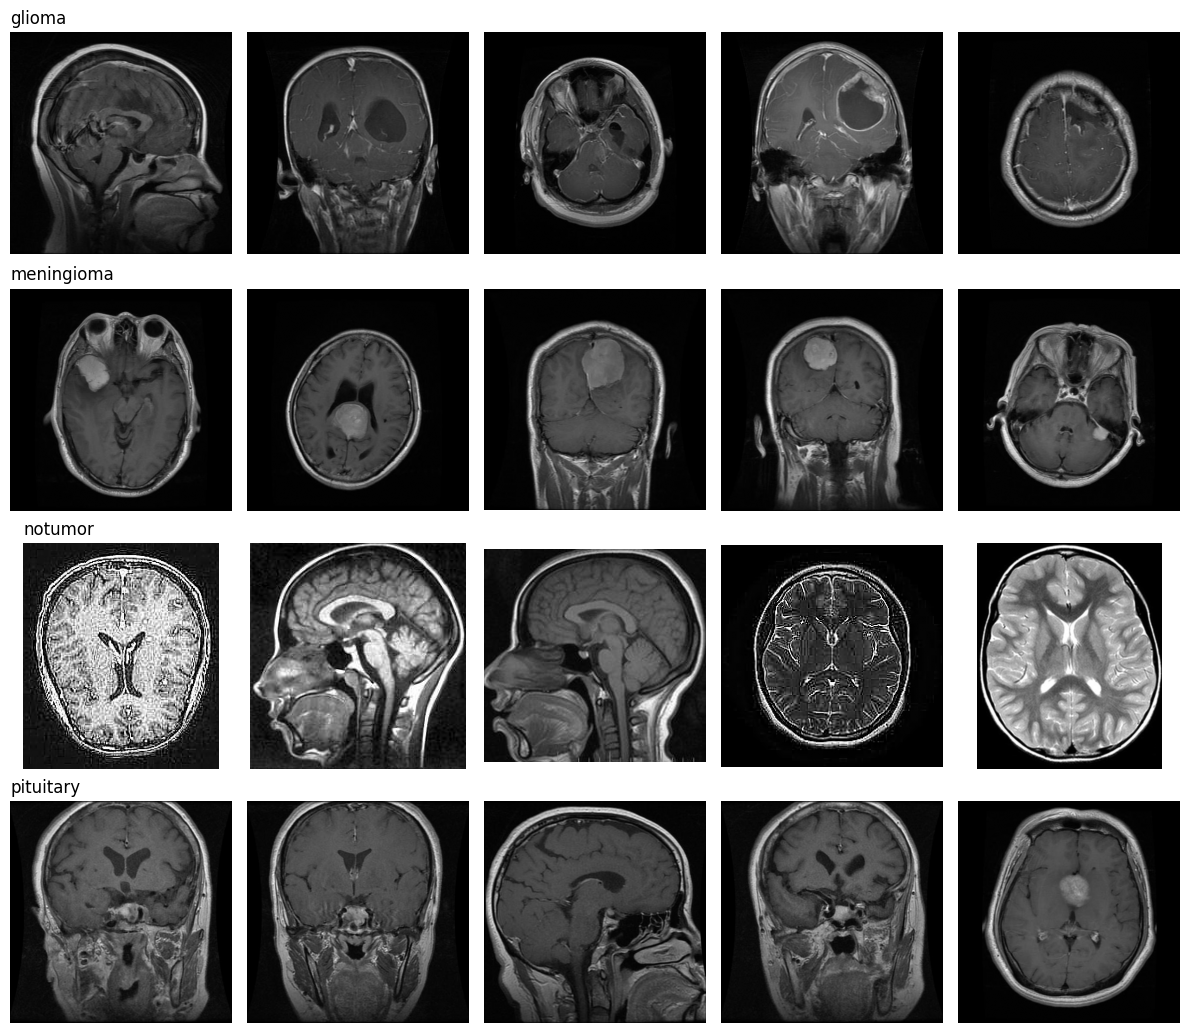

In [8]:
fig, axes = plt.subplots(len(CLASS_NAMES), 5, figsize=(12, 2.6 * len(CLASS_NAMES)))
for r, cls in enumerate(CLASS_NAMES):
    paths = train_full_df[train_full_df.label == cls].sample(5, random_state=SEED)["path"]
    for c, p in enumerate(paths):
        axes[r, c].imshow(Image.open(p).convert("L"), cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cls, loc="left", fontsize=12)
plt.tight_layout(); plt.show()

## Step 3 — Split and preprocess
- **Split:** `Training/` → 85% train, 15% validation. `stratify` keeps the class ratio the same in both.
  The `Testing/` folder is used **only once, at the very end**.
- **Preprocess:** convert to RGB (copies the gray channel 3 times, because pretrained models expect 3 channels),
  resize to 224×224, normalize with ImageNet mean/std.
- **Augmentation (train only):** small rotation, horizontal flip, small brightness/contrast change.
  No vertical flip, because real brain scans are never upside down.

In [9]:
train_df, val_df = train_test_split(
    train_full_df, test_size=VAL_RATIO, stratify=train_full_df["label"], random_state=SEED
)
print(f"train: {len(train_df)} | val: {len(val_df)} | test: {len(test_df)}")

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class MRIDataset(Dataset):
    def __init__(self, df, transform):
        self.paths  = df["path"].tolist()
        self.labels = [CLASS_TO_IDX[l] for l in df["label"]]
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]

NUM_WORKERS = 2
train_loader = DataLoader(MRIDataset(train_df, train_tf), batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS)
val_loader   = DataLoader(MRIDataset(val_df,   eval_tf),  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(MRIDataset(test_df,  eval_tf),  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

train: 4760 | val: 840 | test: 1600


## Step 4 — Build the model (transfer learning)
EfficientNet-B0 was already trained on ImageNet (1.2 million photos), so it already knows edges, shapes and textures.
We replace its last layer with a new one that outputs **4 classes**, then fine-tune the whole model on MRI images.
It is small (about 5M parameters), so it will also run fast in the web app later.

In [10]:
model = timm.create_model(MODEL_NAME, pretrained=PRETRAINED, num_classes=len(CLASS_NAMES)).to(device)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"{MODEL_NAME}: {n_params:.1f}M parameters")

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

efficientnet_b0: 4.0M parameters


## Step 5 — Train
- **Loss:** cross-entropy (standard for classification).
- **Optimizer:** AdamW, with a cosine schedule that slowly lowers the learning rate.
- **Mixed precision (AMP):** faster on GPU, same accuracy.
- After each epoch we check **validation accuracy** and keep a copy of the model **only when it gets better**.

In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
use_amp = device == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type="cuda", enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = []
best_val_acc, best_state = 0.0, None
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    scheduler.step()
    history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss, train_acc=tr_acc, val_acc=va_acc))
    flag = ""
    if va_acc > best_val_acc:
        best_val_acc, best_state = va_acc, copy.deepcopy(model.state_dict())
        flag = "  <- best so far, saved"
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time()-t0:.0f}s{flag}")

model.load_state_dict(best_state)
print(f"\nBest validation accuracy: {best_val_acc:.4f}")

Epoch  1/12 | train loss 0.730 acc 0.817 | val loss 0.236 acc 0.925 | 155s  <- best so far, saved
Epoch  2/12 | train loss 0.179 acc 0.942 | val loss 0.139 acc 0.961 | 21s  <- best so far, saved
Epoch  3/12 | train loss 0.106 acc 0.962 | val loss 0.125 acc 0.964 | 21s  <- best so far, saved
Epoch  4/12 | train loss 0.069 acc 0.977 | val loss 0.072 acc 0.973 | 21s  <- best so far, saved
Epoch  5/12 | train loss 0.040 acc 0.987 | val loss 0.077 acc 0.977 | 21s  <- best so far, saved
Epoch  6/12 | train loss 0.031 acc 0.991 | val loss 0.055 acc 0.983 | 21s  <- best so far, saved
Epoch  7/12 | train loss 0.027 acc 0.991 | val loss 0.065 acc 0.979 | 22s
Epoch  8/12 | train loss 0.020 acc 0.993 | val loss 0.048 acc 0.983 | 21s
Epoch  9/12 | train loss 0.012 acc 0.996 | val loss 0.056 acc 0.980 | 22s
Epoch 10/12 | train loss 0.014 acc 0.995 | val loss 0.048 acc 0.977 | 21s
Epoch 11/12 | train loss 0.012 acc 0.997 | val loss 0.052 acc 0.980 | 22s
Epoch 12/12 | train loss 0.016 acc 0.994 | val 

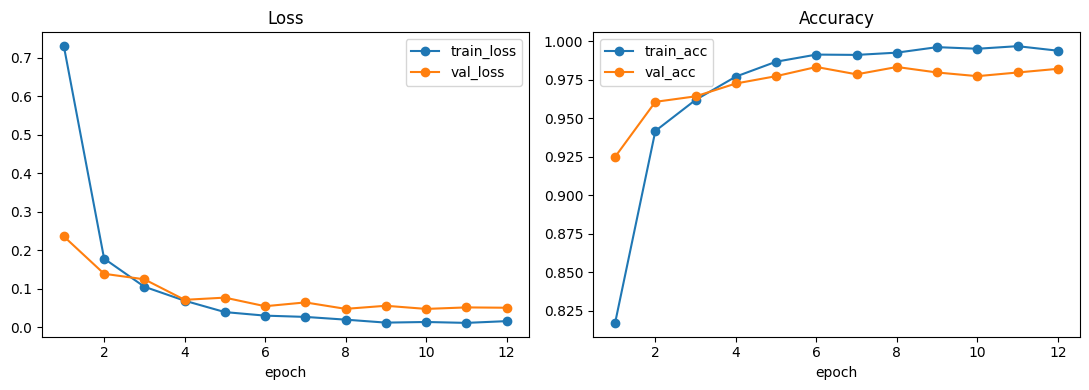

In [12]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
h.plot(x="epoch", y=["train_loss", "val_loss"], ax=ax[0], title="Loss", marker="o")
h.plot(x="epoch", y=["train_acc", "val_acc"], ax=ax[1], title="Accuracy", marker="o")
plt.tight_layout(); plt.show()

**How to read these curves:** if train accuracy keeps going up but validation accuracy goes down, the model is
**overfitting** (memorizing). That's why we kept the epoch with the best *validation* accuracy, not the last one.

## Step 6 — Evaluate on the test set (only once!)
- **Accuracy:** overall % correct.
- **Precision / recall per class.** For tumors, **recall** matters most: recall = "of all real tumors, how many did we find?"
  A missed tumor is the worst mistake.
- **Confusion matrix:** shows which classes get mixed up.

Test accuracy: 0.9425

              precision    recall  f1-score   support

      glioma      0.991     0.807     0.890       400
  meningioma      0.898     0.965     0.930       400
     notumor      0.915     1.000     0.956       400
   pituitary      0.980     0.998     0.989       400

    accuracy                          0.943      1600
   macro avg      0.946     0.943     0.941      1600
weighted avg      0.946     0.943     0.941      1600



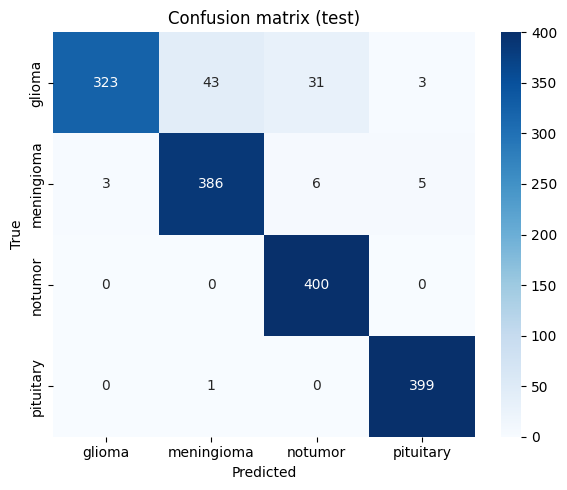

In [13]:
@torch.no_grad()
def get_logits(loader):
    model.eval()
    all_logits, all_y = [], []
    for x, y in loader:
        all_logits.append(model(x.to(device)).float().cpu())
        all_y.append(y)
    return torch.cat(all_logits), torch.cat(all_y)

test_logits, test_y = get_logits(test_loader)
test_pred = test_logits.argmax(1)

print(f"Test accuracy: {accuracy_score(test_y, test_pred):.4f}\n")
print(classification_report(test_y, test_pred, target_names=CLASS_NAMES, digits=3))

cm = confusion_matrix(test_y, test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test)")
plt.tight_layout(); plt.show()

## Step 7 — Make the confidence honest (temperature scaling)
Neural networks are often **overconfident**: they may say "99% sure" even when wrong.
Temperature scaling learns **one number T** on the validation set. We divide the model output by T before softmax.
It does **not** change which class is predicted (accuracy stays the same); it only fixes the confidence values.

We measure this with **ECE (Expected Calibration Error)**: the gap between "how confident" and "how often correct".
Lower is better.

This matters because apps 3 and 4 use confidence to decide **"refer to a doctor"**.

In [14]:
val_logits, val_y = get_logits(val_loader)

log_T = torch.zeros(1, requires_grad=True)          # T = exp(log_T), so T is always positive
opt_T = torch.optim.LBFGS([log_T], lr=0.1, max_iter=200)
def closure():
    opt_T.zero_grad()
    loss = F.cross_entropy(val_logits / log_T.exp(), val_y)
    loss.backward()
    return loss
opt_T.step(closure)
TEMPERATURE = log_T.exp().item()
print(f"Learned temperature T = {TEMPERATURE:.3f}  (T > 1 means the model was overconfident)")

def ece(logits, y, n_bins=15):
    probs = F.softmax(logits, 1)
    conf, pred = probs.max(1)
    correct = pred.eq(y).float()
    bins = torch.linspace(0, 1, n_bins + 1)
    e = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.float().mean() * (conf[m].mean() - correct[m].mean()).abs()
    return e.item()

print(f"Test ECE before: {ece(test_logits, test_y):.4f}")
print(f"Test ECE after : {ece(test_logits / TEMPERATURE, test_y):.4f}")

Learned temperature T = 1.291  (T > 1 means the model was overconfident)
Test ECE before: 0.0408
Test ECE after : 0.0340


## Step 8 — Check Grad-CAM heatmaps
Grad-CAM shows **which part of the image pushed the model toward its answer** (red = important).
We use the last convolution layer (`conv_head`). Look at the results: does the red area sit on the tumor?

The bottom section shows **mistakes**, which are useful to discuss in your presentation.

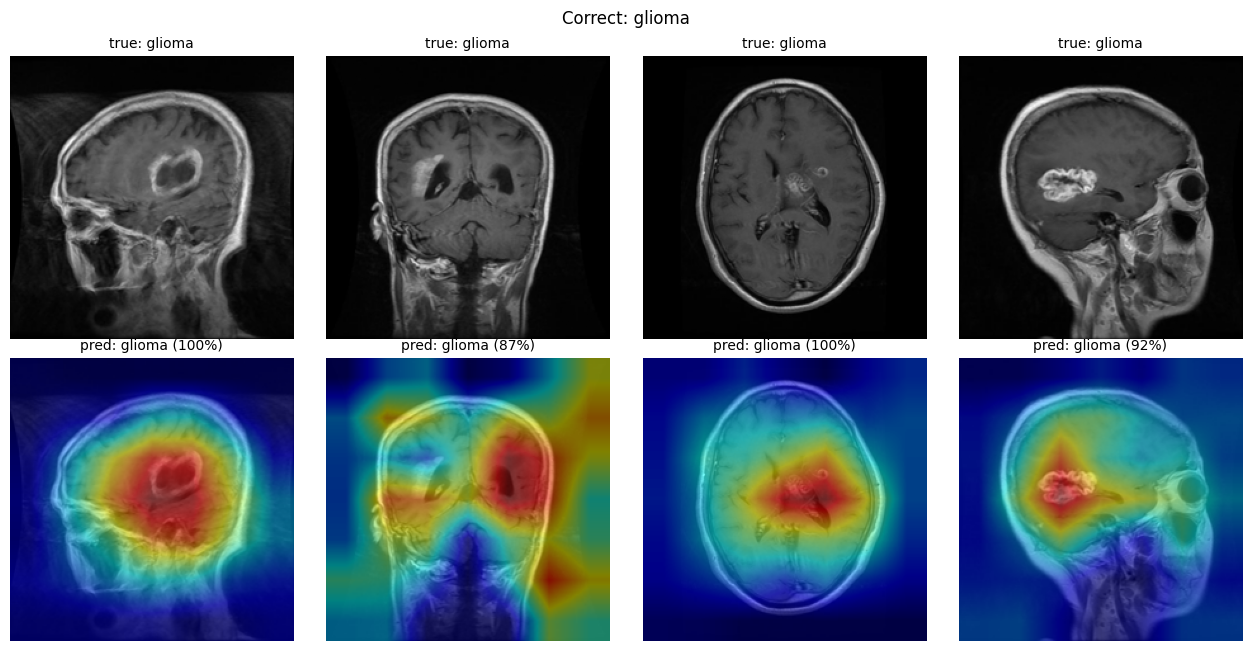

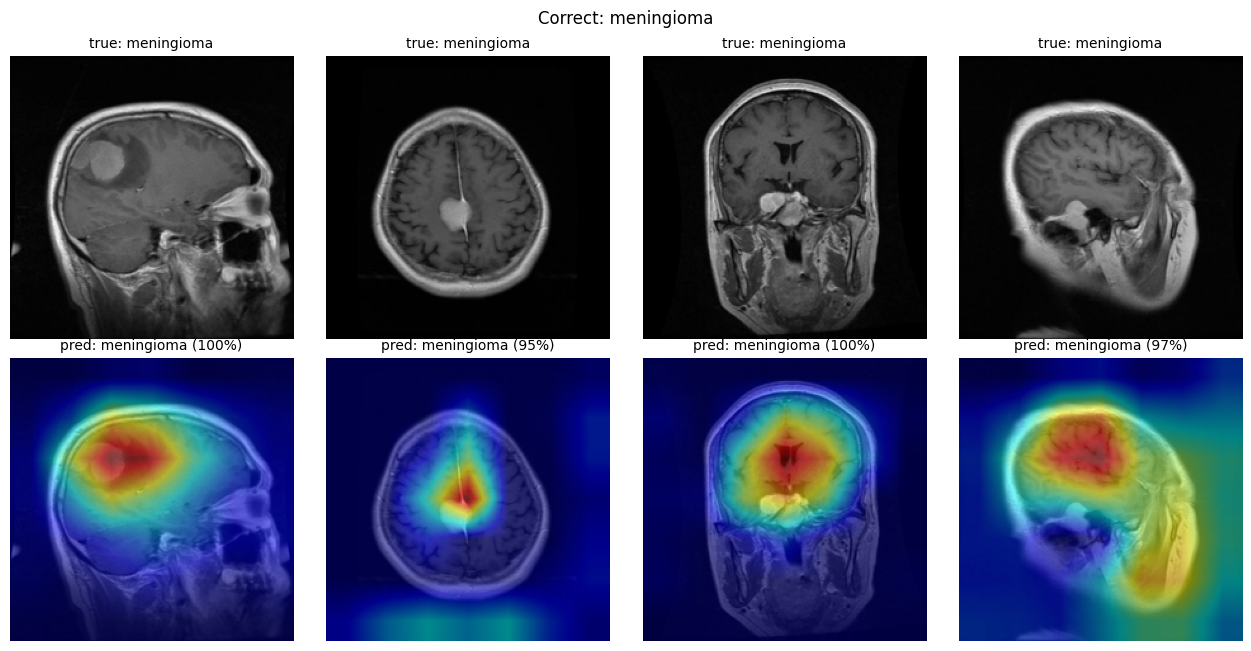

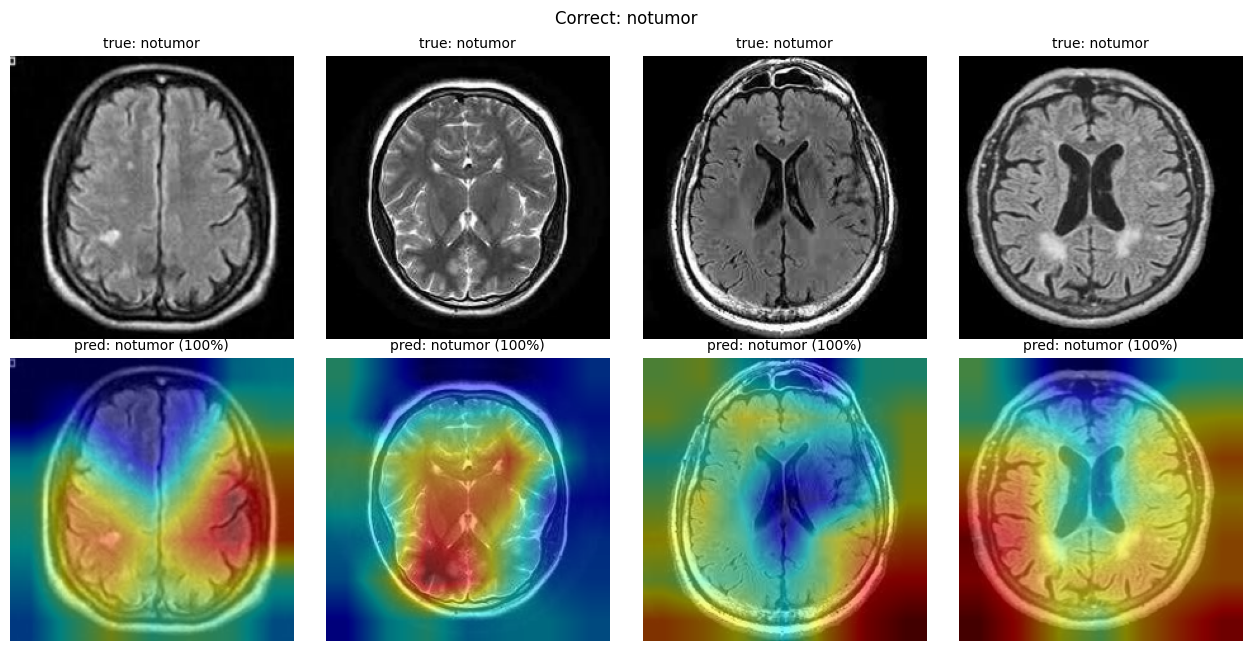

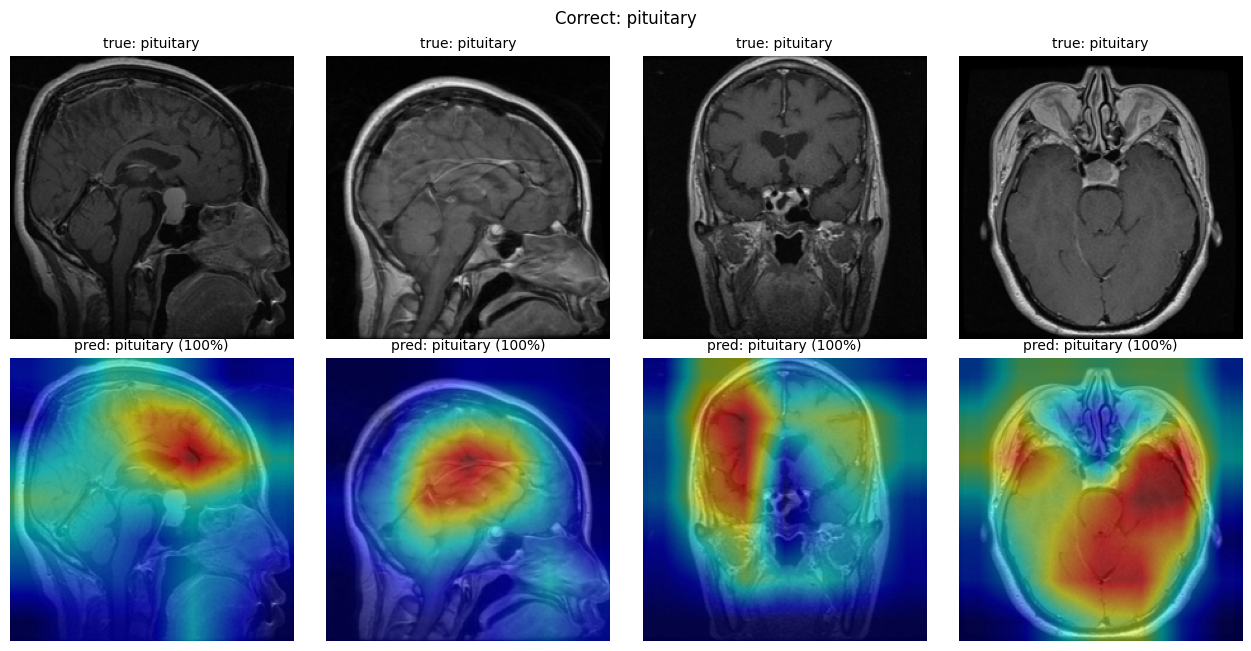

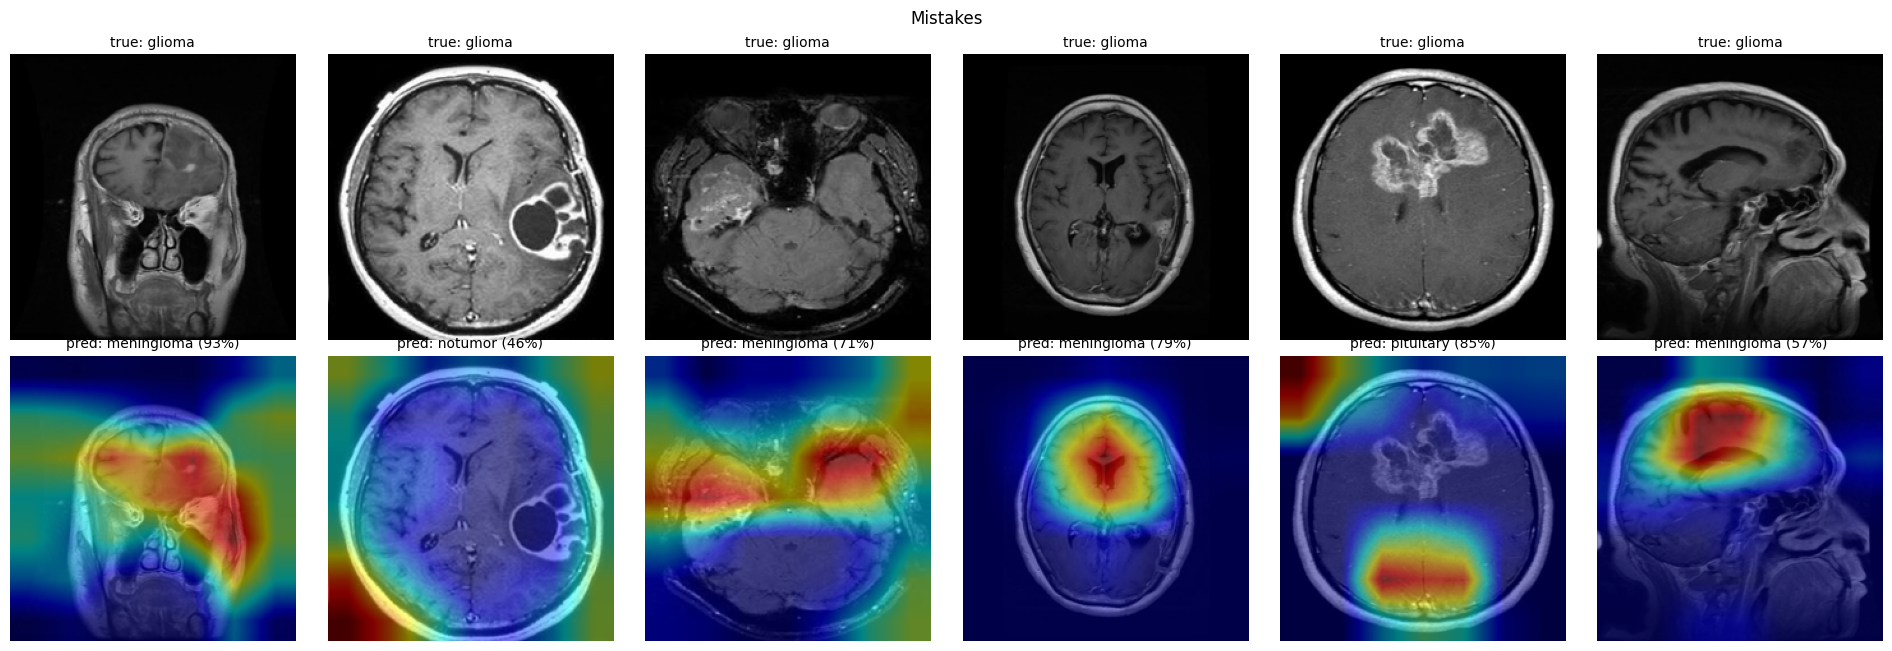

In [15]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

cam = GradCAM(model=model, target_layers=[model.conv_head])

def gradcam_overlay(path):
    img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    rgb = np.asarray(img, dtype=np.float32) / 255.0
    x = eval_tf(Image.open(path).convert("RGB")).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(x).float() / TEMPERATURE, 1)[0].cpu()
    pred = int(probs.argmax())
    heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(pred)])[0]
    return rgb, show_cam_on_image(rgb, heat, use_rgb=True), pred, float(probs[pred])

def show_cases(df, title, n=4):
    if len(df) == 0:
        print(f"No cases for: {title}"); return
    df = df.sample(min(n, len(df)), random_state=SEED)
    fig, axes = plt.subplots(2, len(df), figsize=(3.2 * len(df), 6.6), squeeze=False)
    for c, (_, row) in enumerate(df.iterrows()):
        rgb, overlay, pred, conf = gradcam_overlay(row["path"])
        axes[0, c].imshow(rgb); axes[0, c].set_title(f"true: {row['label']}", fontsize=10)
        axes[1, c].imshow(overlay); axes[1, c].set_title(f"pred: {CLASS_NAMES[pred]} ({conf:.0%})", fontsize=10)
        axes[0, c].axis("off"); axes[1, c].axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

results = test_df.copy()
results["pred"] = [CLASS_NAMES[i] for i in test_pred.tolist()]

for cls in CLASS_NAMES:
    show_cases(results[(results.label == cls) & (results.pred == cls)], f"Correct: {cls}", n=4)
show_cases(results[results.label != results.pred], "Mistakes", n=6)

## Step 9 — Save everything
We save the weights **plus** everything the apps need to use the model the same way:
class names, image size, normalization values and the temperature T.

After this cell, open the **Output** panel on the right → `/kaggle/working/` → download **`best_model.pth`**.

In [16]:
checkpoint = {
    "model_name":  MODEL_NAME,
    "state_dict":  model.state_dict(),
    "class_names": CLASS_NAMES,
    "img_size":    IMG_SIZE,
    "mean":        MEAN,
    "std":         STD,
    "temperature": TEMPERATURE,
    "test_accuracy": float(accuracy_score(test_y, test_pred)),
}
torch.save(checkpoint, OUT_DIR / "best_model.pth")
print("Saved:", OUT_DIR / "best_model.pth")
print({k: v for k, v in checkpoint.items() if k != "state_dict"})

Saved: /kaggle/working/best_model.pth
{'model_name': 'efficientnet_b0', 'class_names': ['glioma', 'meningioma', 'notumor', 'pituitary'], 'img_size': 224, 'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225], 'temperature': 1.2912728786468506, 'test_accuracy': 0.9425}


## Quick check — load the saved file like the app will
This proves the saved file works on its own (this is the same code the apps will use in Part B).

In [17]:
ckpt = torch.load(OUT_DIR / "best_model.pth", map_location="cpu", weights_only=False)
m2 = timm.create_model(ckpt["model_name"], pretrained=False, num_classes=len(ckpt["class_names"]))
m2.load_state_dict(ckpt["state_dict"]); m2.eval()

x = eval_tf(Image.open(test_df.iloc[0]["path"]).convert("RGB")).unsqueeze(0)
with torch.no_grad():
    p = F.softmax(m2(x) / ckpt["temperature"], 1)[0]
print("True label:", test_df.iloc[0]["label"])
print({c: round(float(v), 3) for c, v in zip(ckpt["class_names"], p)})

True label: glioma
{'glioma': 0.073, 'meningioma': 0.076, 'notumor': 0.003, 'pituitary': 0.847}
